# BT4012 Fraud Analytics Group 14: Model comparison and misclassification analysis
Compares RGCN-MLP (`model.ipynb`) with XGBoost (`model_classical.ipynb`) at a 5% review budget per test year (2019-2022), and looks at the frauds both models miss. Uses the saved predictions only
- NOTE: repeat candidate = fraud last year, first-time candidate = no fraud last year

## Libraries
Importing of necessary libraries

In [24]:
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score

## Configuration
Set folder paths, test years, review budgets and chart colours

In [25]:
# Folder paths
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = ROOT / "results"
EDGE_PATH = PROCESSED_DIR / "graph" / "company_edges.parquet"

# Row keys and test years
KEYS = ["nodeID", "Year"]
TEST_YEARS = [2019, 2020, 2021, 2022]

# Review budget (top 5% of companies per year), plus the budgets and first-time shares for the business table
BUDGET = 0.05
BUDGETS = [0.02, 0.05, 0.10]
FIRST_TIME_SHARES = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]

# Bootstrap settings
N_BOOT, SEED = 2000, 0

# Model names and their prediction columns, and the groups for the misclassification analysis
MODELS = {"XGBoost": "xgb", "MLP": "mlp", "RGCN": "rgcn", "RGCN-MLP": "ens"}
GROUPS = ["missed by both", "caught by at least one", "first-time non-fraud"]

# Chart colours and shared chart style
COLORS = {"RGCN-MLP": "#1baf7a", "XGBoost": "#eb6834", "MLP": "#2a78d6", "RGCN": "#7a5af5",
          "History rule only": "#52514e", "Perfect ranking": "#b8b7b1"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1",
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
                     "legend.frameon": False, "font.size": 9.5})

## Helpers
Functions for flagging the top 5%, counting frauds caught and the paired bootstrap

In [26]:
# Number of review slots for n companies (round() removes small float errors before rounding up)
def n_slots(n, share=BUDGET):
    return int(np.ceil(round(share * n, 9)))


# True for the k highest scores, ties go to the earlier row
def top_k(scores, k):
    mask = np.zeros(len(scores), dtype=bool)
    order = np.argsort(-np.asarray(scores, dtype=float), kind="stable")
    mask[order[:k]] = True
    return mask


# Flag the top 5% of each year's companies by col, choosing only among rows (default: everyone)
def flag_top(col, rows=None, share=BUDGET):
    if rows is None:
        rows = pd.Series(True, index=wide.index)
    flags = pd.Series(False, index=wide.index)
    for year in TEST_YEARS:
        in_year = wide["Year"] == year
        idx = wide.index[in_year & rows]
        k = n_slots(in_year.sum(), share)
        flags[idx] = top_k(wide.loc[idx, col].to_numpy(), k)
    return flags


# Frauds caught per year in the top 5%
def caught_by_year(col):
    flagged = wide.loc[flag_top(col), ["Year", "Label"]]
    return flagged.groupby("Year")["Label"].sum()


# Two review queues: repeat candidates get (1 - first_time_share) of the budget, first-time candidates get the rest
# Unused repeat slots go to the first-time queue
def caught_at_budget(score_col, budget, first_time_share):
    out = dict.fromkeys(["repeat reviews", "repeat caught", "first-time reviews", "first-time caught"], 0)
    for _, g in wide.groupby("Year"):
        y = g["Label"].to_numpy()
        s = g[score_col].to_numpy()
        repeat = g["fraud_last_year"].to_numpy() == 1
        slots = n_slots(len(g), budget)
        repeat_slots = min(n_slots(len(g), budget * (1 - first_time_share)), repeat.sum())
        for name, rows, k in [("repeat", repeat, repeat_slots), ("first-time", ~repeat, slots - repeat_slots)]:
            out[f"{name} reviews"] += k
            out[f"{name} caught"] += int(y[rows][top_k(s[rows], k)].sum())
    out["total caught"] = out["repeat caught"] + out["first-time caught"]
    return out


# Metrics used in the bootstrap (k = number of review slots)
METRICS = {"caught": lambda y, s, k: y[top_k(s, k)].sum(),
           "PR-AUC": lambda y, s, k: average_precision_score(y, s),
           "ROC-AUC": lambda y, s, k: roc_auc_score(y, s)}


# Paired bootstrap of model A minus model B, resampling companies within each year
# "caught" is summed over years, the AUCs are averaged over years
def paired_bootstrap(col_a, col_b, rows, metrics):
    data = []
    for y in TEST_YEARS:
        in_year = wide["Year"] == y
        values = wide.loc[in_year & rows, ["Label", col_a, col_b]].to_numpy()
        data.append((values, n_slots(in_year.sum())))

    # A minus B for one set of resampled rows per year
    def difference(metric, samples):
        diffs = []
        for (d, k), i in zip(data, samples):
            diffs.append(METRICS[metric](d[i, 0], d[i, 1], k) - METRICS[metric](d[i, 0], d[i, 2], k))
        return np.sum(diffs) if metric == "caught" else np.mean(diffs)

    rows_out = []
    for metric in metrics:
        # Same resamples for every metric
        rng = np.random.default_rng(SEED)
        boot = []
        for _ in range(N_BOOT):
            samples = [np.sort(rng.integers(0, len(d), len(d))) for d, _ in data]
            boot.append(difference(metric, samples))
        boot = np.array(boot)
        observed = difference(metric, [np.arange(len(d)) for d, _ in data])
        rows_out.append({"metric": metric, "difference": observed,
                         "95% low": np.percentile(boot, 2.5), "95% high": np.percentile(boot, 97.5),
                         "A better %": 100 * (boot > 0).mean(), "tie %": 100 * (boot == 0).mean(),
                         "B better %": 100 * (boot < 0).mean()})
    return pd.DataFrame(rows_out).set_index("metric")

## Loading predictions
Loads the RGCN and XGBoost predictions and adds last year's fraud label

In [27]:
# Label and last year's label for each company-year
labels = pd.read_csv(DATA_DIR / "splits" / "temporal_splits.csv")[KEYS + ["Label"]].drop_duplicates(KEYS)
last_year = labels.assign(Year=labels["Year"] + 1).rename(columns={"Label": "fraud_last_year"})
labels = labels.merge(last_year, on=KEYS, how="left")
labels["fraud_last_year"] = labels["fraud_last_year"].fillna(0).astype(int)
LAST_LABEL_YEAR = labels["Year"].max()

# RGCN predictions, one column per model
rgcn = pd.read_csv(RESULTS_DIR / "rgcn_predictions.csv")
wide = rgcn.query("model == 'ens'")[KEYS + ["Label"]]
for m in ["ens", "mlp", "rgcn"]:
    scores = rgcn.query("model == @m")[KEYS + ["model_score"]].rename(columns={"model_score": m})
    wide = wide.merge(scores, on=KEYS)

# XGBoost predictions: each test-year row appears once per split, the first copy is from the split where it is the test year
classical = pd.read_csv(RESULTS_DIR / "classical_predictions.csv")
classical = classical[classical["Year"].isin(TEST_YEARS)].drop_duplicates(KEYS + ["model"], keep="first")

# Check that these rows give the same AUCs as classical_results.csv
reported = pd.read_csv(RESULTS_DIR / "classical_results.csv").drop_duplicates(["model", "test_year"])
reported = reported.set_index(["model", "test_year"])["test_auc"]
for (m, year), r in classical[classical["model"].isin(["xgb", "xgb_tuned"])].groupby(["model", "Year"]):
    assert abs(roc_auc_score(r["Label"], r["score"]) - reported[(m, year)]) < 1e-6, f"{m} {year}: AUC differs from classical_results.csv"
for m in ["xgb", "xgb_tuned"]:
    scores = classical.loc[classical["model"] == m, KEYS + ["score"]].rename(columns={"score": m})
    wide = wide.merge(scores, on=KEYS)

# History rule: adding 1 puts last year's frauds at the top
wide = wide.merge(labels[KEYS + ["fraud_last_year"]], on=KEYS, how="left").sort_values(KEYS).reset_index(drop=True)
for m in ["ens", "mlp", "rgcn", "xgb", "xgb_tuned"]:
    wide[f"{m}_hist"] = wide[m] + wide["fraud_last_year"]

# Repeat candidates, first-time candidates and frauds
REPEAT, FIRST, FRAUD = wide["fraud_last_year"] == 1, wide["fraud_last_year"] == 0, wide["Label"] == 1
print(f"{len(wide):,} test company-years, {FRAUD.sum()} frauds ({(FRAUD & FIRST).sum()} first-time, {(FRAUD & REPEAT).sum()} repeat)")

17,985 test company-years, 727 frauds (204 first-time, 523 repeat)


## 1. Frauds caught at 5%
Frauds caught per test year by each model, compared with the history rule alone and a perfect ranking
- NOTE: xgb_tuned is only for reference since it was tuned on 2021, which is also a test year

In [28]:
# Frauds caught per year for each model
headline = pd.DataFrame({"RGCN-MLP": caught_by_year("ens_hist"),
                         "XGBoost (score alone)": caught_by_year("xgb"),
                         "XGBoost + history rule": caught_by_year("xgb_hist"),
                         "xgb_tuned + history rule (reference)": caught_by_year("xgb_tuned_hist")}).T

# History rule only: last year's frauds first, everyone else in random order (mean of 100 seeds)
random_runs = []
for seed in range(100):
    wide["random_hist"] = np.random.default_rng(seed).random(len(wide)) + wide["fraud_last_year"]
    random_runs.append(caught_by_year("random_hist"))
headline.loc["History rule only"] = pd.DataFrame(random_runs).mean()

# Perfect ranking: every fraud is caught until the slots run out
perfect = []
for y in TEST_YEARS:
    in_year = wide["Year"] == y
    perfect.append(min(wide.loc[in_year, "Label"].sum(), n_slots(in_year.sum())))
headline.loc["Perfect ranking"] = perfect
headline["Total"] = headline.sum(axis=1)
headline.round(1)

Year,2019,2020,2021,2022,Total
RGCN-MLP,144.0,131.0,137.0,101.0,513.0
XGBoost (score alone),80.0,87.0,70.0,60.0,297.0
XGBoost + history rule,142.0,131.0,137.0,100.0,510.0
xgb_tuned + history rule (reference),142.0,131.0,137.0,99.0,509.0
History rule only,136.3,131.0,136.4,98.4,502.1
Perfect ranking,191.0,207.0,183.0,123.0,704.0


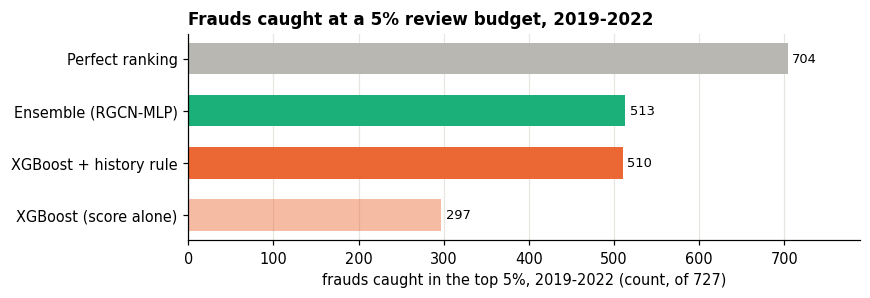

In [29]:
# Total frauds caught, with perfect ranking at the top
CHART = {"Perfect ranking": COLORS["Perfect ranking"], "Ensemble (RGCN-MLP)": COLORS["RGCN-MLP"],
         "XGBoost + history rule": COLORS["XGBoost"], "XGBoost (score alone)": COLORS["XGBoost"]}
totals = headline.rename(index={"RGCN-MLP": "Ensemble (RGCN-MLP)"}).loc[list(CHART), "Total"][::-1]
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(totals.index, totals, color=[CHART[n] for n in totals.index], height=0.6)
# Lighter bar for XGBoost without the history rule
bars[0].set_alpha(0.45)
ax.bar_label(bars, labels=[f"{v:.0f}" for v in totals], padding=3, fontsize=8.5)
ax.set(xlabel=f"frauds caught in the top 5%, 2019-2022 (count, of {FRAUD.sum()})", xlim=(0, totals.max() * 1.12),
       title="Frauds caught at a 5% review budget, 2019-2022")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

### RGCN-MLP vs XGBoost
Paired bootstrap of frauds caught, and how much of the budget goes to last year's frauds

In [30]:
# A = RGCN-MLP, B = XGBoost, both with the history rule
display(paired_bootstrap("ens_hist", "xgb_hist", pd.Series(True, index=wide.index), ["caught"]).round(2))

# Review slots per year and how many are left after last year's frauds
budget = pd.DataFrame({"slots (5%)": [n_slots((wide["Year"] == y).sum()) for y in TEST_YEARS],
                       "repeat candidates": REPEAT.groupby(wide["Year"]).sum().to_numpy()}, index=TEST_YEARS)
budget["left for first-time"] = (budget["slots (5%)"] - budget["repeat candidates"]).clip(lower=0)
budget.loc["Total"] = budget.sum()
filled = budget.loc["Total", "slots (5%)"] - budget.loc["Total", "left for first-time"]
print(f"{filled} of {budget.loc['Total', 'slots (5%)']} slots ({filled / budget.loc['Total', 'slots (5%)']:.0%}) go to last year's frauds")
budget

,difference,95% low,95% high,A better %,tie %,B better %
metric,,,,,,
caught,3.0,-7.0,13.0,68.65,6.7,24.65


775 of 901 slots (86%) go to last year's frauds


,slots (5%),repeat candidates,left for first-time
2019,191,221,0
2020,214,210,4
2021,239,201,38
2022,257,173,84
Total,901,805,126


## 2. First-time vs repeat frauds
Repeat and first-time candidates flagged under the history rule, then each model ranking only the first-time candidates with the full budget

In [31]:
# Flags under the history rule for each model
FLAGS = {name: flag_top(f"{m}_hist") for name, m in MODELS.items()}

# Repeat and first-time candidates flagged and caught
queue_counts = {}
for name in ["RGCN-MLP", "XGBoost"]:
    queue_counts[name] = {"repeat flagged": (FLAGS[name] & REPEAT).sum(),
                          "repeat frauds caught": (FLAGS[name] & REPEAT & FRAUD).sum(),
                          "first-time flagged": (FLAGS[name] & FIRST).sum(),
                          "first-time frauds caught": (FLAGS[name] & FIRST & FRAUD).sum()}
display(pd.DataFrame(queue_counts).T)

# Full budget on first-time candidates only
FT_FLAGS = {name: flag_top(m, rows=FIRST) for name, m in MODELS.items()}

# Frauds caught, PR-AUC and ROC-AUC per model and year
rows = []
for name, m in MODELS.items():
    for year in TEST_YEARS:
        in_year = wide["Year"] == year
        sub = wide[in_year & FIRST]
        rows.append({"model": name, "Year": year, "caught": (FT_FLAGS[name] & FRAUD & in_year).sum(),
                     "PR-AUC": average_precision_score(sub["Label"], sub[m]),
                     "ROC-AUC": roc_auc_score(sub["Label"], sub[m])})
first_time = pd.DataFrame(rows).pivot(index="model", columns="Year").reindex(list(MODELS))

# Total caught and mean AUCs over the four years
first_time[("caught", "Total")] = first_time["caught"].sum(axis=1)
first_time[("PR-AUC", "Mean")] = first_time["PR-AUC"].mean(axis=1)
first_time[("ROC-AUC", "Mean")] = first_time["ROC-AUC"].mean(axis=1)
first_time = first_time.sort_index(axis=1, level=0, sort_remaining=False)
first_time.round(3)

,repeat flagged,repeat frauds caught,first-time flagged,first-time frauds caught
RGCN-MLP,775,509,126,4
XGBoost,775,507,126,3


PR-AUC                             ROC-AUC                       \
Year       2019   2020   2021   2022   Mean    2019   2020   2021   2022   
model                                                                      
XGBoost   0.043  0.060  0.024  0.023  0.037   0.751  0.708  0.687  0.824   
MLP       0.045  0.061  0.027  0.032  0.041   0.770  0.737  0.702  0.861   
RGCN      0.048  0.060  0.021  0.038  0.042   0.763  0.733  0.685  0.861   
RGCN-MLP  0.047  0.061  0.023  0.036  0.042   0.771  0.739  0.702  0.863   

                caught                       
Year       Mean   2019 2020 2021 2022 Total  
model                                        
XGBoost   0.742     12   18    8    7    45  
MLP       0.767     11   17    8    9    45  
RGCN      0.760     10   16    6   11    43  
RGCN-MLP  0.769     11   16    7   11    45

In [32]:
# A = RGCN-MLP, B = XGBoost, first-time candidates only
paired_bootstrap("ens", "xgb", FIRST, ["caught", "PR-AUC", "ROC-AUC"]).round(3)

,difference,95% low,95% high,A better %,tie %,B better %
metric,,,,,,
caught,0.000,-14.000,12.00,44.2,5.0,50.8
PR-AUC,0.004,-0.008,0.02,78.2,0.0,21.8
ROC-AUC,0.026,-0.006,0.06,94.9,0.0,5.1


### Overlap between the models
First-time frauds caught by each model, and the 2019 repeat frauds (the only year with more repeat candidates than slots)

In [33]:
# Which model caught each first-time fraud
a, b = FT_FLAGS["RGCN-MLP"], FT_FLAGS["XGBoost"]
overlap = pd.Series(np.select([a & b, a & ~b, ~a & b], ["both", "only RGCN-MLP", "only XGBoost"], "neither"), index=wide.index)
display(pd.crosstab(wide.loc[FIRST & FRAUD, "Year"], overlap[FIRST & FRAUD], margins=True, margins_name="Total"))

# 2019 repeat frauds caught by each model
r19 = (wide["Year"] == 2019) & REPEAT & FRAUD
a19, b19 = FLAGS["RGCN-MLP"][r19], FLAGS["XGBoost"][r19]
print(f"2019 repeat frauds ({r19.sum()}): both {(a19 & b19).sum()}, only RGCN-MLP {(a19 & ~b19).sum()}, "
      f"only XGBoost {(~a19 & b19).sum()}, neither {(~a19 & ~b19).sum()}")

col_0,both,neither,only RGCN-MLP,only XGBoost,Total
Year,,,,,
2019,4,37,7,8,56
2020,11,53,5,7,76
2021,3,35,4,5,47
2022,5,12,6,2,25
Total,23,137,22,22,204


2019 repeat frauds (158): both 131, only RGCN-MLP 13, only XGBoost 11, neither 3


## 3. Missed first-time frauds
Compares first-time frauds missed by both models, those caught by at least one, and first-time non-frauds
- NOTE: impairments use absolute values because CSMAR switched their sign in 2019

In [34]:
# Group of each company-year
wide["group"] = np.select([FIRST & FRAUD & ~(a | b), FIRST & FRAUD & (a | b), FIRST & ~FRAUD], GROUPS, "repeat candidate")

# Financial columns and ratios
FIN = {"A001000000": "assets", "A002000000": "liabilities", "B002000000": "net_profit", "B001100000": "revenue",
       "A001111000": "receivables", "B001212000": "asset_impairment", "B001307000": "credit_impairment"}
fin = pd.read_parquet(PROCESSED_DIR / "tabular_clean", columns=KEYS + list(FIN)).rename(columns=FIN).astype({"Year": int})
assets = fin["assets"].where(fin["assets"] > 0)
fin = fin.assign(size=np.log(assets), leverage=fin["liabilities"] / assets, roa=fin["net_profit"] / assets,
                 loss=(fin["net_profit"] < 0).astype(float).where(fin["net_profit"].notna()),
                 receivables_to_assets=fin["receivables"] / assets,
                 impairment=(fin["asset_impairment"].abs().fillna(0) + fin["credit_impairment"].abs().fillna(0)) / assets)

# Revenue growth against last year's revenue
prev_revenue = fin[KEYS + ["revenue"]].assign(Year=fin["Year"] + 1).rename(columns={"revenue": "revenue_prev"})
fin = fin.merge(prev_revenue, on=KEYS, how="left")
fin["revenue_growth"] = fin["revenue"] / fin["revenue_prev"].where(fin["revenue_prev"] > 0) - 1

# Auditor of each company-year from the Audit edges
audit = []
for year in range(labels["Year"].min(), LAST_LABEL_YEAR + 1):
    e = pd.read_csv(DATA_DIR / str(year) / f"edges{year}.csv", header=None, names=["a", "b", "relation"])
    e = e.query("relation == 'Audit'")
    company_first = e["a"].str.startswith("L")
    audit.append(pd.DataFrame({"nodeID": e["a"].where(company_first, e["b"]),
                               "auditor": e["b"].where(company_first, e["a"]), "Year": year}))
audit = pd.concat(audit).drop_duplicates(KEYS)

# Auditor switch: different auditor from last year
prev_audit = audit.assign(Year=audit["Year"] + 1).rename(columns={"auditor": "auditor_prev"})
fin = fin.merge(audit, on=KEYS, how="left").merge(prev_audit, on=KEYS, how="left")
known = fin["auditor"].notna() & fin["auditor_prev"].notna()
fin["auditor_switch"] = (fin["auditor"] != fin["auditor_prev"]).astype(float).where(known)

# Text flags and industry
text = pd.read_parquet(PROCESSED_DIR / "text_features.parquet", columns=KEYS + ["has_text", "is_truncated"])
industry_cols = [c for c in pq.ParquetDataset(str(PROCESSED_DIR / "tabular_features")).schema.names if c.startswith("industry_")]
industry = pd.read_parquet(PROCESSED_DIR / "tabular_features", columns=KEYS + industry_cols).astype({"Year": int})
onehot = industry[industry_cols].to_numpy()
industry_names = np.array([c.removeprefix("industry_") for c in industry_cols])
industry["industry"] = np.where(onehot.any(axis=1), industry_names[onehot.argmax(axis=1)], "none")

# Join everything for the three groups
profile = (wide.loc[wide["group"].isin(GROUPS), KEYS + ["group"]]
           .merge(fin, on=KEYS, how="left")
           .merge(text, on=KEYS, how="left")
           .merge(industry[KEYS + ["industry"]], on=KEYS, how="left"))

# Medians for numbers, % of companies for yes/no features
MEDIANS = {"size": "Size: log total assets", "leverage": "Leverage", "roa": "ROA", "revenue_growth": "Revenue growth",
           "receivables_to_assets": "Receivables / assets", "impairment": "Impairment / assets"}
SHARES = {"loss": "Loss-making (%)", "auditor_switch": "Auditor switch (%)", "has_text": "Has text (%)", "is_truncated": "Truncated text (%)"}
by_group = profile.groupby("group")
feature_profile = pd.concat([by_group[list(MEDIANS)].median().rename(columns=MEDIANS),
                             100 * by_group[list(SHARES)].mean().rename(columns=SHARES)], axis=1).T[GROUPS]
feature_profile.loc["companies"] = by_group.size()[GROUPS]
display(feature_profile.round(3))

# 3 most common industries in each group
top_industries = {}
for g in GROUPS:
    industry_share = profile.loc[profile["group"] == g, "industry"].value_counts(normalize=True).head(3)
    top_industries[g] = ", ".join(f"{k} ({v:.0%})" for k, v in industry_share.items())
pd.Series(top_industries, name="3 most common industries").to_frame()

group,missed by both,caught by at least one,first-time non-fraud
Size: log total assets,21.646,21.847,22.067
Leverage,0.405,0.619,0.405
ROA,0.022,-0.095,0.039
Revenue growth,0.039,-0.115,0.086
Receivables / assets,0.120,0.146,0.102
Impairment / assets,0.009,0.045,0.006
Loss-making (%),18.978,74.627,14.444
Auditor switch (%),18.333,25.758,10.875
Has text (%),98.540,100.000,97.985
Truncated text (%),10.219,10.448,15.316


,3 most common industries
missed by both,"C39 (12%), I65 (9%), C26 (7%)"
caught by at least one,"I65 (12%), E48 (7%), R86 (6%)"
first-time non-fraud,"C39 (11%), C35 (7%), C26 (7%)"


### The following year
Share of each group with a loss, large impairment, profit drop or auditor switch in the next year (2019-2021 only, no 2023 data)

In [35]:
# Next year's values for each company-year
nxt = fin[KEYS + ["roa", "impairment", "loss", "auditor"]].assign(Year=fin["Year"] - 1).add_suffix("_next")
nxt = nxt.rename(columns={"nodeID_next": "nodeID", "Year_next": "Year"})
fp = profile[profile["Year"] < LAST_LABEL_YEAR].merge(nxt, on=KEYS, how="left")
fp["roa_change"] = fp["roa_next"] - fp["roa"]

# Large impairment = top 10% of that year's first-time non-frauds, profit drop = bottom 10% change in ROA
reference = fp[fp["group"] == "first-time non-fraud"].groupby("Year")
fp["impairment_cut"] = fp["Year"].map(reference["impairment_next"].quantile(0.9))
fp["roa_change_cut"] = fp["Year"].map(reference["roa_change"].quantile(0.1))

# Each check: (rows where it can be measured, rows where it happened)
FOOTPRINTS = {"loss in the scored year": (fp["loss"].notna(), fp["loss"] == 1),
              "loss next year": (fp["loss_next"].notna(), fp["loss_next"] == 1),
              "large impairment next year": (fp["impairment_next"].notna(), fp["impairment_next"] >= fp["impairment_cut"]),
              "profit drop next year": (fp["roa_change"].notna(), fp["roa_change"] <= fp["roa_change_cut"]),
              "auditor switch next year": (fp["auditor"].notna() & fp["auditor_next"].notna(), fp["auditor_next"] != fp["auditor"])}
footprint = {}
for name, (defined, hit) in FOOTPRINTS.items():
    footprint[name] = {}
    for g in GROUPS:
        in_group = defined & (fp["group"] == g)
        n_hit, n_total = (hit & in_group).sum(), in_group.sum()
        footprint[name][g] = f"{100 * n_hit / n_total:.0f}% ({n_hit}/{n_total})"
footprint = pd.DataFrame(footprint).T
footprint

,missed by both,caught by at least one,first-time non-fraud
loss in the scored year,18% (22/125),70% (38/54),13% (1520/12042)
loss next year,32% (39/123),79% (42/53),17% (1992/11973)
large impairment next year,21% (26/123),57% (30/53),10% (1198/11973)
profit drop next year,17% (21/123),40% (21/53),10% (1198/11973)
auditor switch next year,16% (20/122),26% (14/53),9% (1038/11911)


### How close were the misses?
Score percentile of each missed fraud among the same year's first-time non-frauds, and whether the missed fraud continues into the next year

In [36]:
# Percentile of each missed-by-both fraud among the first-time non-frauds of the same year (100 = above all of them)
rows = []
for name in ["RGCN-MLP", "XGBoost"]:
    m = MODELS[name]
    pct = []
    for y in TEST_YEARS:
        in_year = wide["Year"] == y
        non_fraud = in_year & FIRST & ~FRAUD
        missed_scores = wide.loc[in_year & (wide["group"] == "missed by both"), m]
        pct.append(100 * np.searchsorted(np.sort(wide.loc[non_fraud, m]), missed_scores, side="right") / non_fraud.sum())
    pct = np.concatenate(pct)
    rows.append({"model": name, "median percentile": np.median(pct), "% above 90th": 100 * (pct > 90).mean(), "% below 50th": 100 * (pct < 50).mean()})
display(pd.DataFrame(rows).set_index("model").round(1))

# Number of years each fraud continues, starting from the scored year
fraud_years = set(map(tuple, labels.loc[labels["Label"] == 1, KEYS].to_numpy()))
run_length = []
for n, y in wide[KEYS].to_numpy():
    k = 0
    while (n, y + k) in fraud_years:
        k += 1
    run_length.append(k)
wide["episode_years"] = np.where(FRAUD, run_length, 0)

# A fraud that continues becomes a repeat candidate next year, a one-year fraud never does
reaches_end = FRAUD & (wide["Year"] + wide["episode_years"] - 1 >= LAST_LABEL_YEAR)
outcome = pd.Series(np.select([reaches_end, wide["episode_years"] == 1],
                              ["unknown (reaches 2022)", "one-year fraud: never a repeat candidate"],
                              "continues: repeat candidate next year"), index=wide.index)
missed_outcomes = {}
for name in ["RGCN-MLP", "XGBoost"]:
    missed = FIRST & FRAUD & ~FLAGS[name]
    missed_outcomes[name] = pd.crosstab(wide.loc[missed, "Year"], outcome[missed], margins=True, margins_name="Total")
pd.concat(missed_outcomes, names=["model"])

,median percentile,% above 90th,% below 50th
model,,,
RGCN-MLP,70.2,18.2,24.1
XGBoost,67.9,14.6,27.0


col_0           continues: repeat candidate next year  \
model    Year                                           
RGCN-MLP 2019                                      24   
         2020                                      27   
         2021                                       0   
         2022                                       0   
         Total                                     51   
XGBoost  2019                                      24   
         2020                                      27   
         2021                                       0   
         2022                                       0   
         Total                                     51   

col_0           one-year fraud: never a repeat candidate  \
model    Year                                              
RGCN-MLP 2019                                         23   
         2020                                         23   
         2021                                         20   
         2022                                          0   
         Total                                        66   
XGBoost  2019                                         23   
         2020                                         23   
         2021                                         21   
         2022                                          0   
         Total                                        67   

col_0           unknown (reaches 2022)  Total  
model    Year                                  
RGCN-MLP 2019                        9     56  
         2020                       26     76  
         2021                       26     46  
         2022                       22     22  
         Total                      83    200  
XGBoost  2019                        9     56  
         2020                       26     76  
         2021                       25     46  
         2022                       23     23  
         Total                      83    201

## 4. Why the graph did not help
MLP (no graph) vs RGCN vs RGCN-MLP, with XGBoost for reference (Exhibit 2)

In [37]:
# Exhibit 2: frauds caught at 5% and first-time results for each model
exhibit2 = pd.DataFrame({"caught at 5% (of 727)": {name: FLAGS[name][FRAUD].sum() for name in MODELS},
                         "first-time caught, full budget (of 204)": first_time[("caught", "Total")],
                         "first-time PR-AUC": first_time[("PR-AUC", "Mean")],
                         "first-time ROC-AUC": first_time[("ROC-AUC", "Mean")]})
display(exhibit2.round(3))
# A = RGCN, B = MLP, first-time candidates only
paired_bootstrap("rgcn", "mlp", FIRST, ["caught", "PR-AUC", "ROC-AUC"]).round(3)

,caught at 5% (of 727),"first-time caught, full budget (of 204)",first-time PR-AUC,first-time ROC-AUC
XGBoost,510,45,0.037,0.742
MLP,510,45,0.041,0.767
RGCN,516,43,0.042,0.760
RGCN-MLP,513,45,0.042,0.769


,difference,95% low,95% high,A better %,tie %,B better %
metric,,,,,,
caught,-2.000,-12.000,8.000,30.50,8.0,61.50
PR-AUC,0.001,-0.008,0.009,54.15,0.0,45.85
ROC-AUC,-0.007,-0.021,0.008,17.15,0.0,82.85


### Fraud signal in the graph links
Share of edges, coverage and lift of each relation for first-time candidates in the training years (2015-2018)

In [38]:
# Training-year edges with each neighbour's fraud label from last year
edges = pd.read_parquet(EDGE_PATH, filters=[("Year", "in", [2015, 2016, 2017, 2018])])
neighbours = labels.rename(columns={"nodeID": "target_id", "fraud_last_year": "neighbour_fraud_last_year"})
edges = edges.merge(neighbours[["target_id", "Year", "neighbour_fraud_last_year"]], on=["target_id", "Year"], how="left")
candidates = labels[labels["Year"].between(2015, 2018) & (labels["fraud_last_year"] == 0)]
candidate_index = candidates.set_index(KEYS).index

# Lift = fraud rate of companies with a fraud neighbour / fraud rate of those without one
rows = []
for relation, e in list(edges.groupby("relation")) + [("any relation", edges)]:
    has_neighbour = candidate_index.isin(e.set_index(["source_id", "Year"]).index)
    fraud_edges = e[e["neighbour_fraud_last_year"] == 1]
    fraud_neighbour = candidate_index.isin(fraud_edges.set_index(["source_id", "Year"]).index)
    rate_with = candidates["Label"][fraud_neighbour].mean()
    rate_without = candidates["Label"][~fraud_neighbour].mean()
    rows.append({"relation": relation, "edge share %": 100 * len(e) / len(edges), "coverage %": 100 * has_neighbour.mean(),
                 "with a fraud neighbour %": 100 * fraud_neighbour.mean(), "lift": rate_with / rate_without})
del edges
pd.DataFrame(rows).set_index("relation").sort_values("edge share %", ascending=False).round(2)

,edge share %,coverage %,with a fraud neighbour %,lift
relation,,,,
any relation,100.00,100.00,97.93,1.25
shared_auditor,49.84,99.69,91.01,1.66
shared_unlisted_investment,30.92,77.23,42.64,0.82
shared_related_individual,11.49,16.92,11.58,0.90
shared_org_investor,4.38,33.07,22.01,0.93
Investment,1.09,78.74,3.06,0.53
shared_individual_investor,1.08,68.22,18.32,1.08
unlisted_investment_and_related_party,0.45,63.67,6.53,1.13
shared_related_unlisted_firm,0.34,36.22,4.78,0.90


### RGCN vs MLP
Score correlation, frauds RGCN gains and loses at 5% compared with MLP, and the graph position of those companies

In [39]:
# Score correlation, separately for first-time and repeat candidates
print("first-time correlation:", round(wide.loc[FIRST, "rgcn"].corr(wide.loc[FIRST, "mlp"]), 3),
      "| repeat correlation:", round(wide.loc[REPEAT, "rgcn"].corr(wide.loc[REPEAT, "mlp"]), 3))

# Frauds flagged by RGCN but not MLP (gained), and by MLP but not RGCN (lost)
gained, lost = FLAGS["RGCN"] & ~FLAGS["MLP"] & FRAUD, FLAGS["MLP"] & ~FLAGS["RGCN"] & FRAUD
display(pd.DataFrame({"flags differ": (FLAGS["RGCN"] != FLAGS["MLP"]).sum(),
                      "gained: first-time": (gained & FIRST).sum(), "gained: repeat": (gained & REPEAT).sum(),
                      "lost: first-time": (lost & FIRST).sum(), "lost: repeat": (lost & REPEAT).sum()}, index=["RGCN vs MLP"]))

# Degree and most common relation of each company in the test years
test_edges = pd.read_parquet(EDGE_PATH, columns=["source_id", "relation", "Year"], filters=[("Year", "in", TEST_YEARS)])
counts = test_edges.groupby(["source_id", "Year", "relation"]).size()
degree = counts.groupby(level=[0, 1]).sum()
main_relation = counts.groupby(level=[0, 1]).idxmax().str[2]
graph = pd.DataFrame({"degree": degree, "main relation": main_relation})
graph = wide[KEYS].join(graph, on=KEYS)
del test_edges

# Median degree and top 2 relations of each group
compare_groups = {"all companies": pd.Series(True, index=wide.index), "frauds gained by RGCN": gained, "frauds lost by RGCN": lost}
graph_summary = {}
for name, mask in compare_groups.items():
    top_relations = graph.loc[mask, "main relation"].value_counts(normalize=True).head(2)
    graph_summary[name] = {"companies": mask.sum(), "median degree": graph.loc[mask, "degree"].median(),
                           "main relation": ", ".join(f"{k} ({v:.0%})" for k, v in top_relations.items())}
pd.DataFrame(graph_summary).T

first-time correlation: 0.864 | repeat correlation: 0.651


,flags differ,gained: first-time,gained: repeat,lost: first-time,lost: repeat
RGCN vs MLP,134,5,9,4,4


,companies,median degree,main relation
all companies,17985,338.0,"shared_auditor (88%), shared_unlisted_investme..."
frauds gained by RGCN,14,147.5,"shared_auditor (93%), shared_unlisted_investme..."
frauds lost by RGCN,8,272.5,"shared_auditor (75%), shared_unlisted_investme..."


## 5. Business integration
Frauds caught with a repeat queue and a first-time queue at different budgets and first-time shares
- NOTE: trade-off table only, choosing a setting from it would use the test labels

In [40]:
# Frauds caught for each model, budget and first-time share
rows = []
for name in ["RGCN-MLP", "XGBoost"]:
    for b in BUDGETS:
        for s in FIRST_TIME_SHARES:
            rows.append({"model": name, "budget": f"{b:.0%}", "first-time share": f"{s:.0%}", **caught_at_budget(MODELS[name], b, s)})
tradeoff = pd.DataFrame(rows)
display(tradeoff.pivot_table(index=["budget", "first-time share"], columns="model",
                             values=["total caught", "first-time caught", "repeat caught"], sort=False))

# Frauds per 100 reviews in each queue at the 5% budget
at5 = tradeoff[tradeoff["budget"] == "5%"].set_index(["model", "first-time share"])
per_100 = 100 * at5[["repeat caught", "first-time caught"]].to_numpy() / at5[["repeat reviews", "first-time reviews"]].to_numpy()
pd.DataFrame(per_100, index=at5.index, columns=["repeat queue", "first-time queue"]).round(1).rename_axis(columns="frauds per 100 reviews at 5%")

total caught         first-time caught          \
model                       RGCN-MLP XGBoost          RGCN-MLP XGBoost   
budget first-time share                                                  
2%     0%                      250.0   259.0               0.0     0.0   
       10%                     230.0   240.0               1.0     2.0   
       20%                     210.0   218.0               4.0     2.0   
       30%                     193.0   195.0               7.0     5.0   
       40%                     169.0   166.0               7.0     6.0   
       50%                     147.0   148.0              10.0    11.0   
5%     0%                      513.0   510.0               4.0     3.0   
       10%                     492.0   493.0               8.0     4.0   
       20%                     470.0   472.0              10.0    11.0   
       30%                     434.0   430.0              14.0    11.0   
       40%                     384.0   392.0              18.0    19.0   
       50%                     331.0   340.0              21.0    22.0   
10%    0%                      567.0   570.0              44.0    47.0   
       10%                     567.0   570.0              44.0    47.0   
       20%                     567.0   570.0              44.0    47.0   
       30%                     567.0   570.0              44.0    47.0   
       40%                     567.0   570.0              44.0    47.0   
       50%                     555.0   555.0              46.0    48.0   

                        repeat caught          
model                        RGCN-MLP XGBoost  
budget first-time share                        
2%     0%                       250.0   259.0  
       10%                      229.0   238.0  
       20%                      206.0   216.0  
       30%                      186.0   190.0  
       40%                      162.0   160.0  
       50%                      137.0   137.0  
5%     0%                       509.0   507.0  
       10%                      484.0   489.0  
       20%                      460.0   461.0  
       30%                      420.0   419.0  
       40%                      366.0   373.0  
       50%                      310.0   318.0  
10%    0%                       523.0   523.0  
       10%                      523.0   523.0  
       20%                      523.0   523.0  
       30%                      523.0   523.0  
       40%                      523.0   523.0  
       50%                      509.0   507.0

frauds per 100 reviews at 5%  repeat queue  first-time queue
model    first-time share                                   
RGCN-MLP 0%                           65.7               3.2
         10%                          65.5               4.9
         20%                          66.9               4.7
         30%                          67.3               5.1
         40%                          67.5               5.0
         50%                          68.6               4.7
XGBoost  0%                           65.4               2.4
         10%                          66.2               2.5
         20%                          67.0               5.2
         30%                          67.1               4.0
         40%                          68.8               5.3
         50%                          70.4               4.9

## Limitations
- RGCN-MLP, MLP and RGCN come from a single training run
- The history rule assumes last year's label is known at prediction time
- 2021-2022 labels are incomplete, so some non-frauds may be undetected frauds
- The label mixes accounting and non-accounting violations, so the reasons for misses are only guesses
- No shuffled-edge test was run, so the graph adding no benefit does not mean it carries no signal